In [10]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d

print("--- ВЫБОР ИСТОЧНИКА ДАННЫХ ---")
print("1. Использовать готовую функцию по умолчанию: f(x) = x * sin(x)")
print("2. Ввести свою функцию с клавиатуры")
choice = input("Выберите вариант (1 или 2): ").strip()

if choice == '2':
    user_func_str = input("Введите функцию от x (например, x**3 - 3*x или np.cos(x)): ")
    true_func = lambda x: eval(user_func_str)
    
    xmin = float(input("Введите левую границу интервала (например, 0): "))
    xmax = float(input("Введите правую границу интервала (например, 10): "))
    num_nodes = int(input("Введите количество узлов (например, 6): "))
    
    x_nodes = np.linspace(xmin, xmax, num_nodes)
else:
    true_func = lambda x: x * np.sin(x)
    x_nodes = np.linspace(0, 10, 6)

y_nodes = true_func(x_nodes)

print("\n Узлы x:", np.round(x_nodes, 4))
print(" Узлы y:", np.round(y_nodes, 4))
print(f"Рабочий интервал: [{x_nodes[0]:.2f}, {x_nodes[-1]:.2f}]")

--- ВЫБОР ИСТОЧНИКА ДАННЫХ ---
1. Использовать готовую функцию по умолчанию: f(x) = x * sin(x)
2. Ввести свою функцию с клавиатуры

 Узлы x: [ 0.  2.  4.  6.  8. 10.]
 Узлы y: [ 0.      1.8186 -3.0272 -1.6765  7.9149 -5.4402]
Рабочий интервал: [0.00, 10.00]


 Точка 3.0 успешно прошла проверку (находится внутри интервала).

--- РЕЗУЛЬТАТЫ ЛИНЕЙНОЙ ИНТЕРПОЛЯЦИИ ---
Значение интерполяции: -0.6043
Истинное значение:     0.4234
Абсолютная погрешность: 1.0277


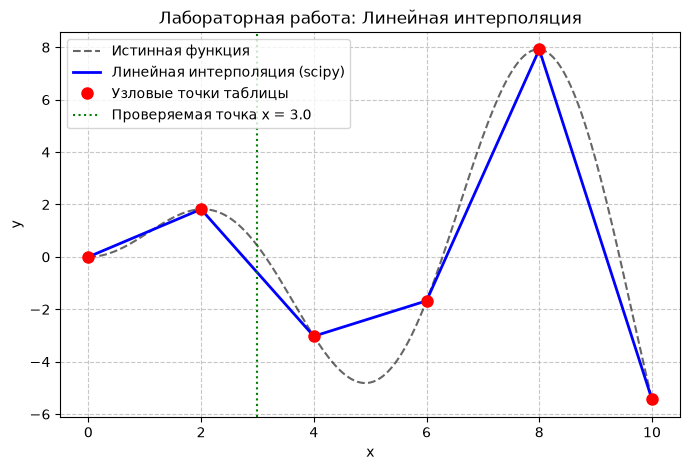

In [11]:
while True:
    try:
        test_point = float(input(f"\nВведите точку x для проверки внутри отрезка [{x_nodes[0]:.2f}, {x_nodes[-1]:.2f}]: "))
    except ValueError:
        print("Ошибка! Введено не число. Попробуйте снова.")
        continue
        
    if x_nodes[0] <= test_point <= x_nodes[-1]:
        print(f" Точка {test_point} успешно прошла проверку (находится внутри интервала).")
        break
    else:
        print(f" Ошибка: точка {test_point} вне границ [{x_nodes[0]:.2f}, {x_nodes[-1]:.2f}]. Введите значение заново.")

linear_interp = interp1d(x_nodes, y_nodes, kind='linear')

# Вычисление значений для графика и проверки
x_dense = np.linspace(x_nodes[0], x_nodes[-1], 200)
y_linear = linear_interp(x_dense)
y_true = true_func(x_dense)

interpolated_value = linear_interp(test_point)
real_value = true_func(test_point)

print(f"\n--- РЕЗУЛЬТАТЫ ЛИНЕЙНОЙ ИНТЕРПОЛЯЦИИ ---")
print(f"Значение интерполяции: {interpolated_value:.4f}")
print(f"Истинное значение:     {real_value:.4f}")
print(f"Абсолютная погрешность: {abs(interpolated_value - real_value):.4f}")

# Построение графика
plt.figure(figsize=(8, 5))
plt.plot(x_dense, y_true, 'k--', label='Истинная функция', alpha=0.6)
plt.plot(x_dense, y_linear, 'b-', label='Линейная интерполяция (scipy)', linewidth=2)
plt.plot(x_nodes, y_nodes, 'ro', label='Узловые точки таблицы', markersize=8)
plt.axvline(test_point, color='g', linestyle=':', label=f'Проверяемая точка x = {test_point}')

plt.title('Лабораторная работа: Линейная интерполяция')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

--- РЕЗУЛЬТАТЫ КВАДРАТИЧНОЙ ИНТЕРПОЛЯЦИИ ---
Значение интерполяции: -0.5188
Истинное значение:     0.4234
Абсолютная погрешность: 0.9422


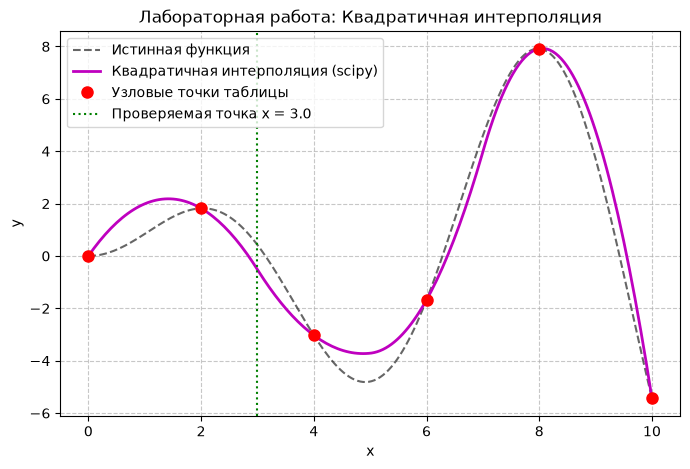

In [12]:
from scipy.interpolate import interp1d

# Создаем квадратичную интерполяцию (полином 2-й степени)
quad_interp = interp1d(x_nodes, y_nodes, kind='quadratic')

# Вычисления для графиков и проверки
y_quad = quad_interp(x_dense)
quad_value = quad_interp(test_point)
real_value = true_func(test_point)

print(f"--- РЕЗУЛЬТАТЫ КВАДРАТИЧНОЙ ИНТЕРПОЛЯЦИИ ---")
print(f"Значение интерполяции: {quad_value:.4f}")
print(f"Истинное значение:     {real_value:.4f}")
print(f"Абсолютная погрешность: {abs(quad_value - real_value):.4f}")

# Построение графика
plt.figure(figsize=(8, 5))
plt.plot(x_dense, y_true, 'k--', label='Истинная функция', alpha=0.6)
plt.plot(x_dense, y_quad, 'm-', label='Квадратичная интерполяция (scipy)', linewidth=2)
plt.plot(x_nodes, y_nodes, 'ro', label='Узловые точки таблицы', markersize=8)
plt.axvline(test_point, color='g', linestyle=':', label=f'Проверяемая точка x = {test_point}')

plt.title('Лабораторная работа: Квадратичная интерполяция')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

--- РЕЗУЛЬТАТЫ КУБИЧЕСКОЙ ИНТЕРПОЛЯЦИИ ---
Значение интерполяции: -0.6169
Истинное значение:     0.4234
Абсолютная погрешность: 1.0402


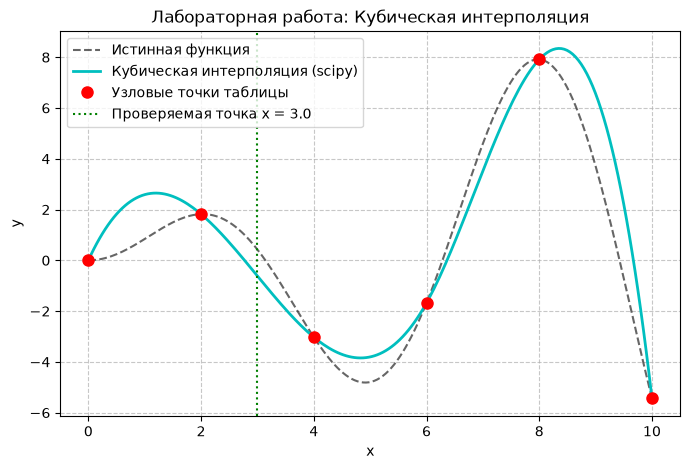

In [13]:
# Создаем кубическую интерполяцию (полином 3-й степени)
cubic_interp = interp1d(x_nodes, y_nodes, kind='cubic')

# Вычисления для графиков и проверки
y_cubic = cubic_interp(x_dense)
cubic_value = cubic_interp(test_point)
real_value = true_func(test_point)

print(f"--- РЕЗУЛЬТАТЫ КУБИЧЕСКОЙ ИНТЕРПОЛЯЦИИ ---")
print(f"Значение интерполяции: {cubic_value:.4f}")
print(f"Истинное значение:     {real_value:.4f}")
print(f"Абсолютная погрешность: {abs(cubic_value - real_value):.4f}")

# Построение графика
plt.figure(figsize=(8, 5))
plt.plot(x_dense, y_true, 'k--', label='Истинная функция', alpha=0.6)
plt.plot(x_dense, y_cubic, 'c-', label='Кубическая интерполяция (scipy)', linewidth=2)
plt.plot(x_nodes, y_nodes, 'ro', label='Узловые точки таблицы', markersize=8)
plt.axvline(test_point, color='g', linestyle=':', label=f'Проверяемая точка x = {test_point}')

plt.title('Лабораторная работа: Кубическая интерполяция')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

--- РЕЗУЛЬТАТЫ (КУБИЧЕСКИЕ СПЛАЙНЫ) ---
Значение интерполяции: -0.6169
Истинное значение:     0.4234
Абсолютная погрешность: 1.0402


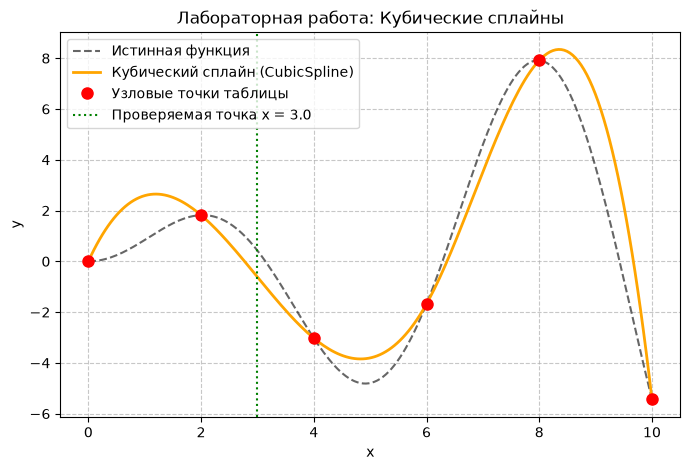

In [14]:
from scipy.interpolate import CubicSpline

# Создаем объект кубического сплайна
cs = CubicSpline(x_nodes, y_nodes)

# Вычисления для графиков и проверки
y_spline = cs(x_dense)
spline_value = cs(test_point)
real_value = true_func(test_point)

print(f"--- РЕЗУЛЬТАТЫ (КУБИЧЕСКИЕ СПЛАЙНЫ) ---")
print(f"Значение интерполяции: {spline_value:.4f}")
print(f"Истинное значение:     {real_value:.4f}")
print(f"Абсолютная погрешность: {abs(spline_value - real_value):.4f}")

# Построение графика
plt.figure(figsize=(8, 5))
plt.plot(x_dense, y_true, 'k--', label='Истинная функция', alpha=0.6)
plt.plot(x_dense, y_spline, 'orange', label='Кубический сплайн (CubicSpline)', linewidth=2)
plt.plot(x_nodes, y_nodes, 'ro', label='Узловые точки таблицы', markersize=8)
plt.axvline(test_point, color='g', linestyle=':', label=f'Проверяемая точка x = {test_point}')

plt.title('Лабораторная работа: Кубические сплайны')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

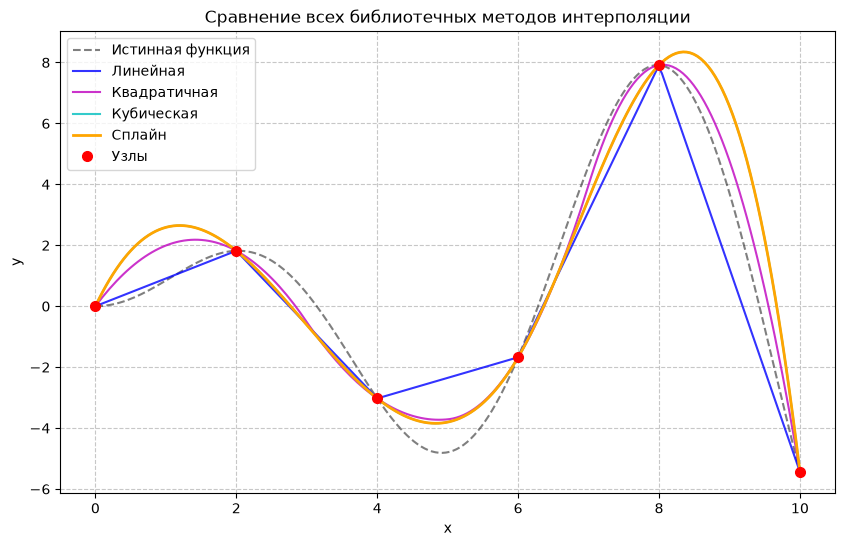

In [15]:
plt.figure(figsize=(10, 6))
plt.plot(x_dense, y_true, 'k--', label='Истинная функция', alpha=0.5, linewidth=1.5)
plt.plot(x_dense, y_linear, 'b-', label='Линейная', alpha=0.8)
plt.plot(x_dense, y_quad, 'm-', label='Квадратичная', alpha=0.8)
plt.plot(x_dense, y_cubic, 'c-', label='Кубическая', alpha=0.8)
plt.plot(x_dense, y_spline, color='orange', label='Сплайн', linewidth=2)
plt.plot(x_nodes, y_nodes, 'ro', label='Узлы', markersize=7)

plt.title('Сравнение всех библиотечных методов интерполяции')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

--- СРАВНЕНИЕ РЕЗУЛЬТАТОВ ---
Истинное значение:0.423360
Библиотечное (scipy):-0.604308
Собственная реализация:-0.604308
Разница между scipy и custom:0.00e+00


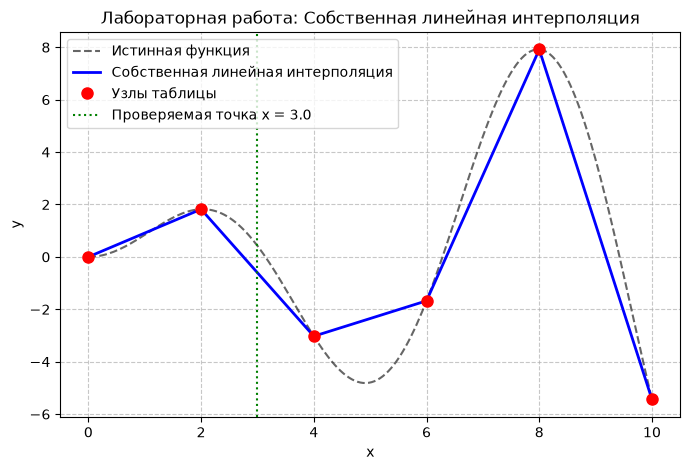

In [16]:
from my_realize import linear_interpolation

y_custom_linear = [linear_interpolation(x_nodes, y_nodes, x) for x in x_dense]

# 3. Считаем значение в нашей проверочной точке test_point
custom_val = linear_interpolation(x_nodes, y_nodes, test_point)
real_val = true_func(test_point)
scipy_val = linear_interp(test_point)

print("--- СРАВНЕНИЕ РЕЗУЛЬТАТОВ ---")
print(f"Истинное значение:{real_val:.6f}")
print(f"Библиотечное (scipy):{scipy_val:.6f}")
print(f"Собственная реализация:{custom_val:.6f}")
print(f"Разница между scipy и custom:{abs(scipy_val - custom_val):.2e}")

# 4. Строим график
plt.figure(figsize=(8, 5))
plt.plot(x_dense, y_true, 'k--', label='Истинная функция', alpha=0.6)
plt.plot(x_dense, y_custom_linear, 'b-', label='Собственная линейная интерполяция', linewidth=2)
plt.plot(x_nodes, y_nodes, 'ro', label='Узлы таблицы', markersize=8)
plt.axvline(test_point, color='g', linestyle=':', label=f'Проверяемая точка x = {test_point}')

plt.title('Лабораторная работа: Собственная линейная интерполяция')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

--- СРАВНЕНИЕ РЕЗУЛЬТАТОВ ---
Истинное значение:0.423360
Библиотечное (scipy):-0.518832
Собственная реализация:0.228742
Разница между scipy и custom:7.48e-01


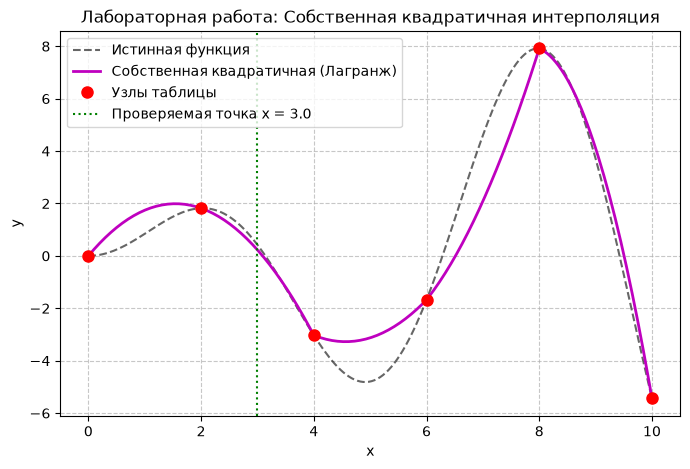

In [17]:
# 1. Импортируем квадратичную функцию из файла my_realize.py
from my_realize import quad_interpolation

# 2. Считаем значения для графика (прогоняем каждую точку из x_dense через нашу функцию)
y_custom_quad = [quad_interpolation(x_nodes, y_nodes, x) for x in x_dense]

# 3. Вычисляем значения в проверочной точке test_point
true_val = test_point * np.sin(test_point) # или ваша исходная функция f(x)
quad_val = quad_interpolation(x_nodes, y_nodes, test_point)
scipy_quad_val = quad_interp(test_point) if 'quad_interp' in globals() else quad_val

diff_quad = abs(scipy_quad_val - quad_val)

print("--- СРАВНЕНИЕ РЕЗУЛЬТАТОВ ---")
print(f"Истинное значение:{true_val:.6f}")
print(f"Библиотечное (scipy):{scipy_quad_val:.6f}")
print(f"Собственная реализация:{quad_val:.6f}")
print(f"Разница между scipy и custom:{diff_quad:.2e}")

# 4. Строим график
plt.figure(figsize=(8, 5))
plt.plot(x_dense, y_true, 'k--', label='Истинная функция', alpha=0.6)
plt.plot(x_dense, y_custom_quad, 'm-', label='Собственная квадратичная (Лагранж)', linewidth=2)
plt.plot(x_nodes, y_nodes, 'ro', label='Узлы таблицы', markersize=8)
plt.axvline(test_point, color='g', linestyle=':', label=f'Проверяемая точка x = {test_point}')

plt.title('Лабораторная работа: Собственная квадратичная интерполяция')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

--- СРАВНЕНИЕ РЕЗУЛЬТАТОВ ---
Истинное значение:0.423360
Библиотечное (scipy):-0.616882
Собственная реализация:-0.575065
Разница между scipy и custom:4.18e-02


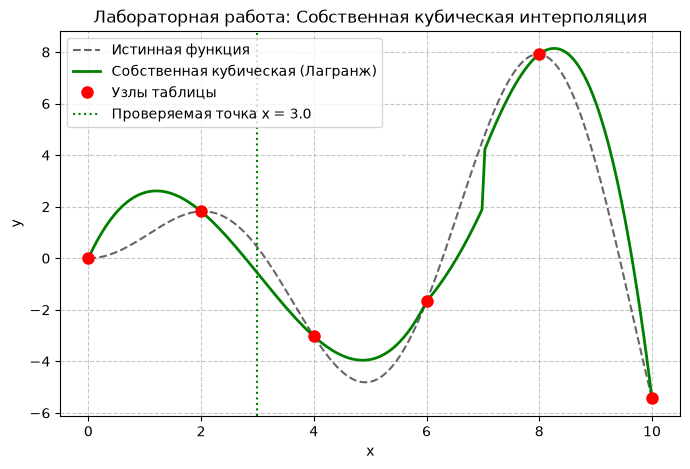

In [18]:
# 1. Импортируем кубическую функцию из файла my_realize.py
from my_realize import cubic_interpolation

# 2. Считаем значения для графика (прогоняем каждую точку из x_dense через нашу функцию)
y_custom_cubic = [cubic_interpolation(x_nodes, y_nodes, x) for x in x_dense]

# 3. Вычисляем значения в проверочной точке test_point
true_val = test_point * np.sin(test_point) # или ваша исходная функция f(x)
cubic_val = cubic_interpolation(x_nodes, y_nodes, test_point)
scipy_cubic_val = cubic_interp(test_point) if 'cubic_interp' in globals() else cubic_val

diff_cubic = abs(scipy_cubic_val - cubic_val)

print("--- СРАВНЕНИЕ РЕЗУЛЬТАТОВ ---")
print(f"Истинное значение:{true_val:.6f}")
print(f"Библиотечное (scipy):{scipy_cubic_val:.6f}")
print(f"Собственная реализация:{cubic_val:.6f}")
print(f"Разница между scipy и custom:{diff_cubic:.2e}")

# 4. Строим график
plt.figure(figsize=(8, 5))
plt.plot(x_dense, y_true, 'k--', label='Истинная функция', alpha=0.6)
plt.plot(x_dense, y_custom_cubic, 'g-', label='Собственная кубическая (Лагранж)', linewidth=2)
plt.plot(x_nodes, y_nodes, 'ro', label='Узлы таблицы', markersize=8)
plt.axvline(test_point, color='g', linestyle=':', label=f'Проверяемая точка x = {test_point}')

plt.title('Лабораторная работа: Собственная кубическая интерполяция')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()